In [86]:
# Import Library
import pandas as pd #data Manipulation/analysis
import numpy as np #Mathematical operations
import matplotlib.pyplot as plt #Visualization
import seaborn as sns #Visualization is mostly used because it is easy
import warnings

warnings.filterwarnings('ignore')

In [87]:
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving AB_NYC_2019.csv to AB_NYC_2019 (2).csv


In [88]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [89]:
df.tail()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2
48894,36487245,Trendy duplex in the very heart of Hell's Kitchen,68119814,Christophe,Manhattan,Hell's Kitchen,40.76404,-73.98933,Private room,90,7,0,NaN,NaN,1,23


In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [91]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [92]:
df.duplicated().sum()

np.int64(0)

In [93]:
df.drop_duplicates(inplace = True)#permanent deletion

In [115]:
df.duplicated().sum()

np.int64(0)

In [95]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [96]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [100]:
columns_to_drop = ['id', 'name', 'host_id', 'host_name', 'last_review']

In [101]:
df_cleaned = df.drop(columns=columns_to_drop, errors='ignore')


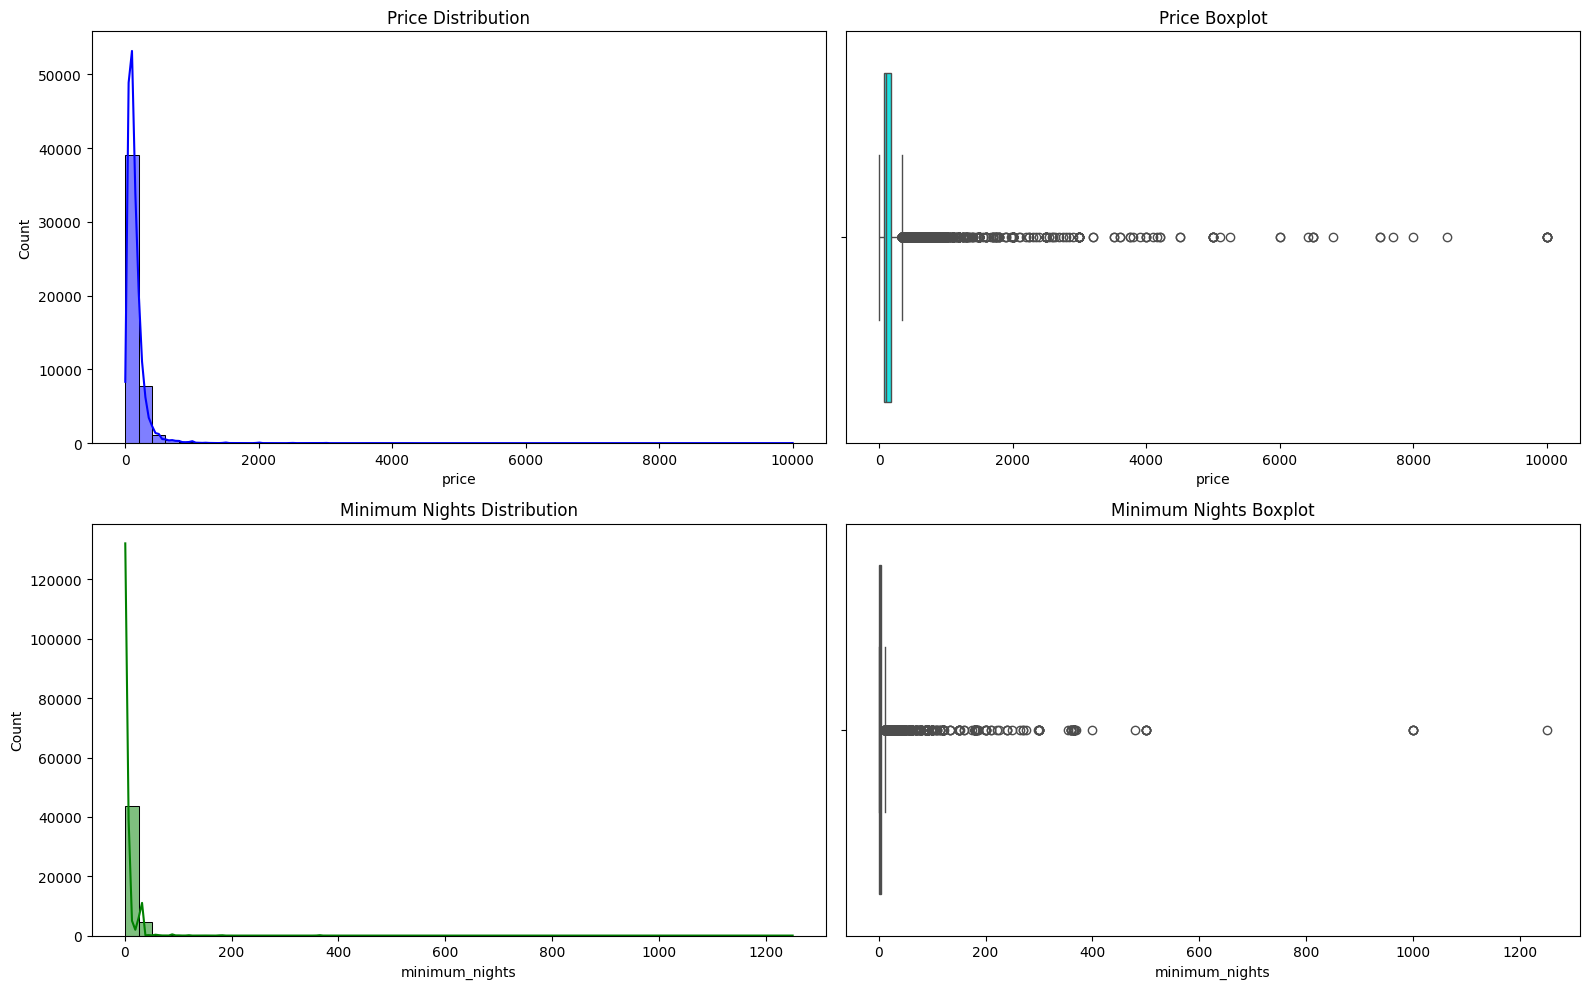

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize a fresh figure with 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Price distribution (Top-Left)
sns.histplot(df_cleaned['price'], bins=50, kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title('Price Distribution')

# 2. Price boxplot (Top-Right)
sns.boxplot(x=df_cleaned['price'], ax=axes[0, 1], color='cyan')
axes[0, 1].set_title('Price Boxplot')

# 3. Minimum Nights distribution (Bottom-Left)
sns.histplot(df_cleaned['minimum_nights'], bins=50, kde=True, ax=axes[1, 0], color='green')
axes[1, 0].set_title('Minimum Nights Distribution')

# 4. Minimum Nights boxplot (Bottom-Right)
sns.boxplot(x=df_cleaned['minimum_nights'], ax=axes[1, 1], color='lime')
axes[1, 1].set_title('Minimum Nights Boxplot')

plt.tight_layout()
plt.show()

In [105]:
price_95 = df_cleaned['price'].quantile(0.95)
min_nights_95 = df_cleaned['minimum_nights'].quantile(0.95)
print(f'95th percentile price: ${price_95:.0f}')
print(f'95th percentile minimum nights: {min_nights_95:.0f}')

95th percentile price: $355
95th percentile minimum nights: 30


In [106]:
df_filtered = df_cleaned[
    (df_cleaned['price'] <= price_95) &
    (df_cleaned['minimum_nights'] <= min_nights_95)
].copy()

print('Rows before filtering:', len(df_cleaned))
print('Rows after filtering:', len(df_filtered))

Rows before filtering: 48895
Rows after filtering: 45759


In [107]:
display(df_filtered[['price', 'minimum_nights']].describe())

,price,minimum_nights
count,45759.000000,45759.000000
mean,122.515024,5.557836
std,71.966885,8.177057
min,0.000000,1.000000
25%,65.000000,1.000000
50%,100.000000,2.000000
75%,160.000000,5.000000
max,355.000000,30.000000


In [108]:
# Drop the high-cardinality neighbourhood column
df_encoded = df_filtered.drop(columns=['neighbourhood'], errors='ignore')

# Also drop last_review as it is a datetime column and not directly suited for basic linear regression
df_encoded = df_encoded.drop(columns=['last_review'], errors='ignore')

display(df_encoded.head())

,neighbourhood_group,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,40.80902,-73.94190,Private room,150,3,0,0.00,1,365
3,Brooklyn,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [109]:
# Apply One-Hot Encoding, dropping the first category to avoid multicollinearity
df_encoded = pd.get_dummies(df_encoded, columns=['neighbourhood_group', 'room_type'], drop_first=True, dtype=int)

# Display the final features after encoding
display(df_encoded.head())

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


In [110]:
from sklearn.model_selection import train_test_split

# Task 5.1: Separate target variable (y) and features (X)
y = df_encoded['price']
X = df_encoded.drop(columns=['price'])

# Task 5.2: Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (36607, 13)
X_test shape: (9152, 13)
y_train shape: (36607,)
y_test shape: (9152,)


In [111]:
from sklearn.linear_model import LinearRegression

# Initialize the model
lr_model = LinearRegression()

# Fit the model on training data
lr_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred = lr_model.predict(X_test)

print("Model training complete! Predictions generated on the testing set.")

Model training complete! Predictions generated on the testing set.


In [112]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Calculate metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Print the results
print("--- Model Performance Evaluation ---")
print(f"R-Squared (R2) Score : {r2:.4f} ({r2*100:.2f}% of variance explained)")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Mean Squared Error (MSE) : {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

--- Model Performance Evaluation ---
R-Squared (R2) Score : 0.4708 (47.08% of variance explained)
Mean Absolute Error (MAE): $38.54
Mean Squared Error (MSE) : 2834.96
Root Mean Squared Error (RMSE): $53.24


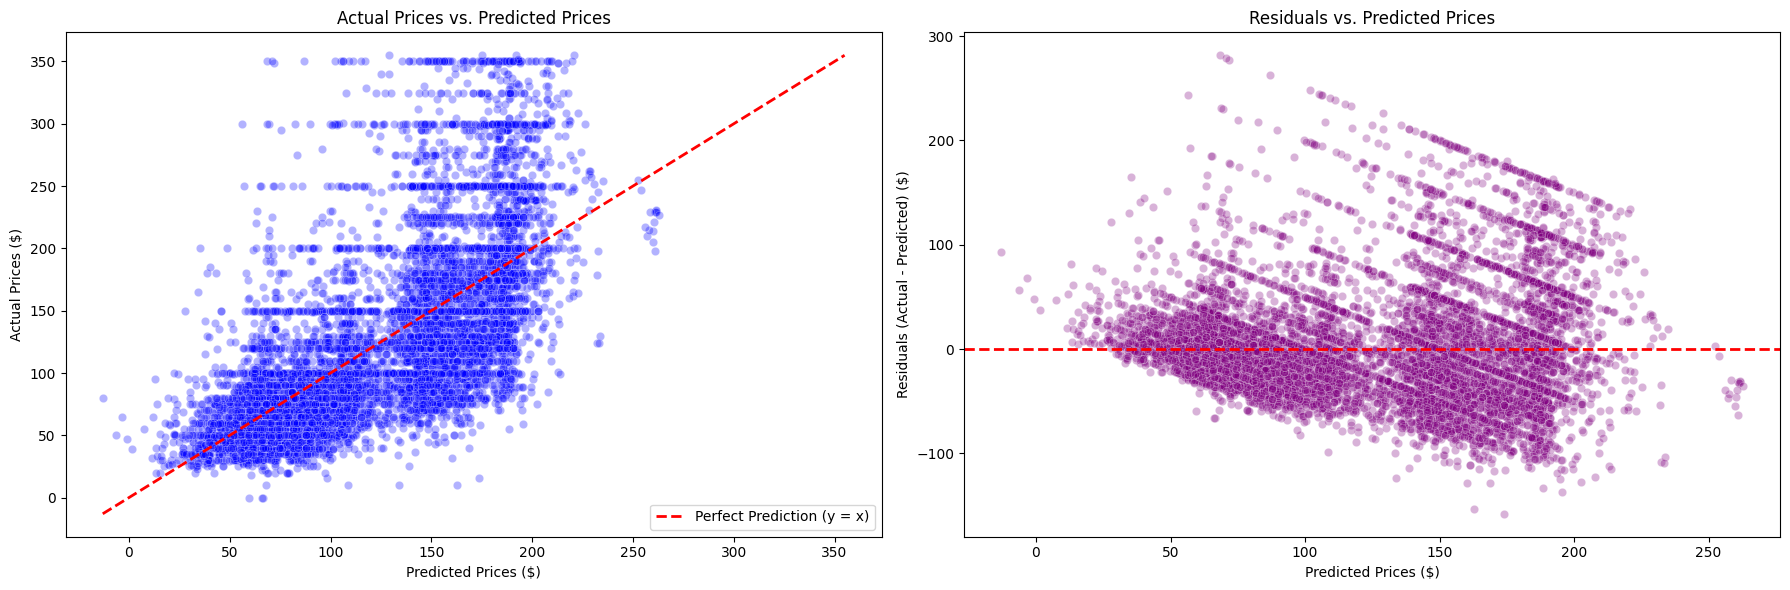

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate residuals
residuals = y_test - y_pred

# Create a side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Subplot 1: Actual vs Predicted Prices
sns.scatterplot(x=y_pred, y=y_test, alpha=0.3, ax=axes[0], color='blue')
# 45-degree diagonal line indicating perfect predictions
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y = x)')
axes[0].set_title('Actual Prices vs. Predicted Prices')
axes[0].set_xlabel('Predicted Prices ($)')
axes[0].set_ylabel('Actual Prices ($)')
axes[0].legend()

# Subplot 2: Residual Plot (Residuals vs. Predicted Values)
sns.scatterplot(x=y_pred, y=residuals, alpha=0.3, ax=axes[1], color='purple')
axes[1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Residuals vs. Predicted Prices')
axes[1].set_xlabel('Predicted Prices ($)')
axes[1].set_ylabel('Residuals (Actual - Predicted) ($)')

plt.tight_layout()
plt.show()

In [114]:
# Compare average prediction mistakes for cheaper and more expensive listings.
results = pd.DataFrame({
    'actual_price': y_test,
    'predicted_price': y_pred
})
results['mistake'] = abs(results['actual_price'] - results['predicted_price'])

median_price = results['actual_price'].median()
cheap = results[results['actual_price'] <= median_price]
expensive = results[results['actual_price'] > median_price]
cheap_mae = cheap['mistake'].mean()
expensive_mae = expensive['mistake'].mean()

print(f'Median test price: ${median_price:.0f}')
print(f'Average mistake for cheaper listings: ${cheap_mae:.2f}')
print(f'Average mistake for expensive listings: ${expensive_mae:.2f}')
if cheap_mae < expensive_mae:
    print('The model predicts cheaper listings more accurately.')
else:
    print('The model predicts expensive listings more accurately.')

print(f'\nR-squared: {r2:.2f} (the model explains about {r2*100:.0f}% of price differences)')
print(f'MAE: ${mae:.2f} (the average prediction mistake is about ${mae:.0f} per night)')

Median test price: $100
Average mistake for cheaper listings: $29.03
Average mistake for expensive listings: $48.58
The model predicts cheaper listings more accurately.

R-squared: 0.47 (the model explains about 47% of price differences)
MAE: $38.54 (the average prediction mistake is about $39 per night)
